In [1]:
library(ggplot2)
library(dplyr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
df = read.table("flow_data.Rin", sep = '\t', header = TRUE)

In [3]:
# Adding average Mbp for CCMP2941 from Wisecaver et al 2023
df <- df %>%
  add_row(new.strain.id = "CCMP2941", Mbp = 485)

In [4]:
df$new.strain.id <- factor(df$new.strain.id, levels=c('12B1','NIES1812','PK2298B4','CC2192B4','CC2192B5','CC2192C1','CC2192D2','CC2192D3','CCMP3037','RCC3703','CCMP2941','8020','8027','12A1','13A5','ARC66','ARC81','ARC82','ARC83','ARC84','PK2297D4','PK2298C6','PK2299B3','PK2300D3','UTEX2797','UTEX2827'))       
head(df)

,Nuclei.Count,Nuclei.Median.B7.A,Nuclei.Mean.B7.A,P1.Count,P1.Median.B7.A,P1.Mean.B7.A,P2.Count,P2.Median.B7.A,P2.Mean.B7.A,strain,Slope,pg.DNA,Mbp,standard,new.strain.id
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<fct>
1,8963,35933,45207,7248,35292,34724,1016,71486,71696,12B1,308686.1,0.1149012,112.6032,True,12B1
2,9904,86826,108451,8476,86002,86741,889,172830,174583,UTEX2797,308686.1,0.2791781,273.5946,True,UTEX2797
3,9965,93347,114715,8758,92801,93630,720,186404,189457,RCC3703,308686.1,0.3012037,295.1797,True,RCC3703
4,5661,76608,84088,5104,76479,77745,252,154728,157384,CCMP3037,308686.1,0.2483280,243.3615,True,CCMP3037
5,9615,86987,116044,7525,86118,86392,1303,171664,172710,12A1,308686.1,0.2795539,273.9628,True,12A1
6,6368,82840,96192,5562,82562,82804,396,165688,166662,Pp2192D3,308686.1,0.2680341,262.6734,False,CC2192D3


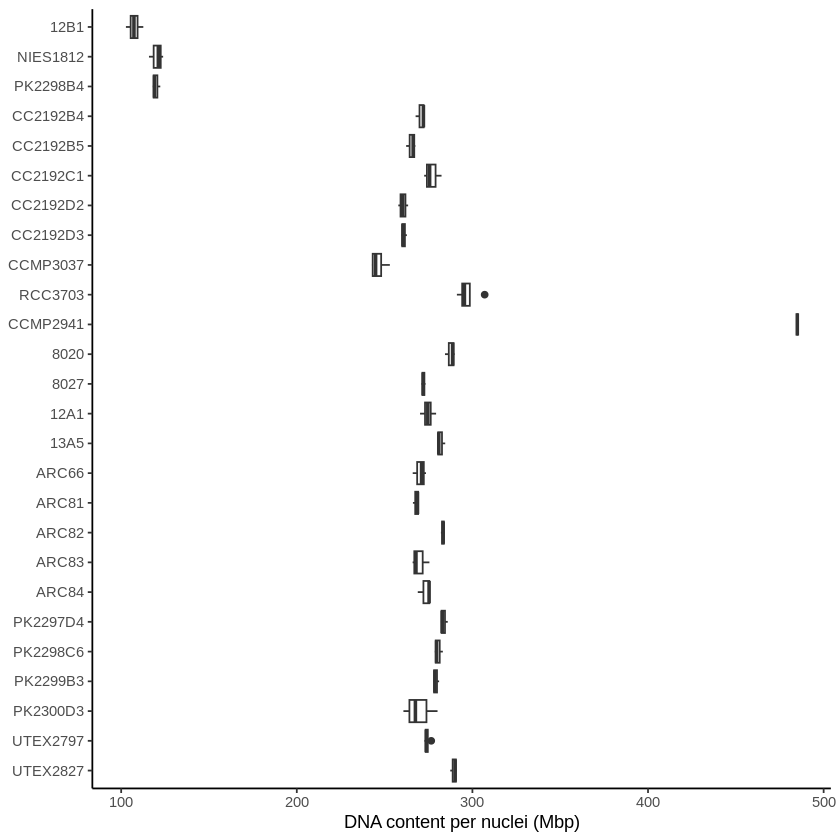

In [5]:
gg = ggplot(data=df, aes(x=new.strain.id, y=Mbp))
gg = gg + geom_boxplot() + scale_x_discrete(limits = rev)
#gg = gg + facet_grid( ~ new.strain.id)
gg = gg + theme_classic() + coord_flip()
gg = gg + labs(y='DNA content per nuclei (Mbp)', x=NULL) 
# gg = gg + scale_color_manual(values=c("#d95f02", "#7570b3", "#1b9e77"))
# gg = gg + theme(legend.position="none")
# gg = gg + theme(axis.title.y=element_blank(), axis.text.y=element_blank(), axis.ticks.y=element_blank())
# gg = gg + theme(text = element_text(size=6))
# gg = gg + theme(panel.spacing = unit(.01, "cm"))
gg

In [6]:
ggsave('flow_plots.pdf', device = "pdf", width = 2.5, height = 6.5, units = "in")